# GIS Workshop 1: Introduction to Spatial Data with Python
## From Tables to Maps with GeoPandas

**Applied GIS & Spatial Analytics Workshop Series**

### Learning objectives
By the end of this 2-hour workshop, you will be able to:
- Explain what makes spatial data different from ordinary tabular data
- Distinguish vector and raster data
- Recognize points, lines, and polygons
- Understand what a coordinate reference system (CRS) is and why it matters
- Load and inspect spatial data with GeoPandas
- Create a basic map of a spatial dataset
- Export a GeoDataFrame for use in GIS Workshop 2

**Portfolio output:** An inspected, exported NJ spatial dataset ready for Workshop 2.

# 1. Key Libraries

### pandas
Works with ordinary tabular data such as CSV files.

### GeoPandas
Extends pandas so that rows can also contain geographic geometry (points, lines, polygons).

### matplotlib
Creates static maps and charts.

### shapely
Provides the geometric objects and spatial operations used by GeoPandas.

### pyogrio
A fast engine used by GeoPandas to read and write many spatial file formats.

In [2]:
!pip -q install geopandas pyogrio

In [3]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Confirm GeoPandas is loaded correctly
print("GeoPandas version:", gpd.__version__)

GeoPandas version: 1.1.4


# 2. GIS in One Sentence

**GIS links information to location so that we can ask questions about where things are, how places differ, and how spatial relationships affect outcomes.**

Examples:
- Where are communities with low broadband access?
- Which neighborhoods are far from libraries?
- Where do flood-risk zones overlap with low-income areas?

# 3. Spatial Data Models

## Vector data
Represents discrete geographic features as shapes.

- **Point:** a single location (e.g., a library, a school)
- **Line:** a linear feature (e.g., a road, a river)
- **Polygon:** an area (e.g., a county, a park)

## Raster data
Represents space as a grid of cells (pixels).

Examples: satellite imagery, elevation surfaces, temperature grids, land-cover maps.

> This workshop focuses on **vector data**. Raster data is introduced in a later workshop.

# Exercise 1 — Think Spatially

For each example below, decide whether you would represent it as a **point, line, polygon, or raster**:

1. Rutgers campus buildings
2. NJ Transit rail routes
3. County boundaries
4. Air temperature across the state
5. Public library locations
6. A hurricane evacuation zone

**Your answers:**
1. ...
2. ...
3. ...
4. ...
5. ...
6. ...

# 4. What is a GeoDataFrame?

A GeoDataFrame behaves exactly like a pandas DataFrame, with one addition: a **geometry** column that stores the shape of each feature.

| GEOID | County | Population | geometry |
|---|---|---|---|
| 34003 | Bergen | 955,732 | POLYGON (...) |
| 34005 | Burlington | 461,860 | POLYGON (...) |

Each row has **attributes** (the data) *and* **geometry** (where it is). This combination is what enables spatial analysis.

In Workshop 2, you will build a GeoDataFrame like this using real NJ county data.

In [5]:
# Load a public GeoJSON of US states
# gpd.read_file() can read from URLs, local files, and zipped shapefiles
states_url = "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
states = gpd.read_file(states_url)

print(type(states))   # GeoDataFrame — not a regular DataFrame
states.head(10)

<class 'geopandas.geodataframe.GeoDataFrame'>


,id,name,density,geometry
0,01,Alabama,94.650,"POLYGON ((-87.3593 35.00118, -85.60668 34.9847..."
1,02,Alaska,1.264,"MULTIPOLYGON (((-131.60202 55.11798, -131.5691..."
2,04,Arizona,57.050,"POLYGON ((-109.0425 37.00026, -109.04798 31.33..."
3,05,Arkansas,56.430,"POLYGON ((-94.47384 36.50186, -90.15254 36.496..."
4,06,California,241.700,"POLYGON ((-123.23326 42.00619, -122.37885 42.0..."
5,08,Colorado,49.330,"POLYGON ((-107.91973 41.00391, -105.72895 40.9..."
6,09,Connecticut,739.100,"POLYGON ((-73.05353 42.03905, -71.79931 42.022..."
7,10,Delaware,464.300,"POLYGON ((-75.41409 39.80446, -75.5072 39.6839..."
8,11,District of Columbia,10065.000,"POLYGON ((-77.03526 38.99387, -76.90929 38.895..."
9,12,Florida,353.400,"POLYGON ((-85.49714 30.99754, -85.00421 31.003..."


# 5. Inspecting Spatial Data

Before mapping any dataset, run these five checks:

| Check | Code | What it tells you |
|---|---|---|
| Sample rows | `.head()` | Field names and sample values |
| Column list | `.columns` | Available attributes |
| Geometry type | `.geometry.geom_type.unique()` | Point / LineString / Polygon |
| CRS | `.crs` | Coordinate reference system |
| Extent | `.total_bounds` | Bounding box (minx, miny, maxx, maxy) |

In [6]:
# Run all five checks on the states dataset
print("Columns:", states.columns.tolist())
print("Geometry types:", states.geometry.geom_type.unique())
print("CRS:", states.crs)
print("Bounds:", states.total_bounds.round(3))

Columns: ['id', 'name', 'density', 'geometry']
Geometry types: ['Polygon' 'MultiPolygon']
CRS: EPSG:4326
Bounds: [-188.905   17.93   -65.627   71.352]


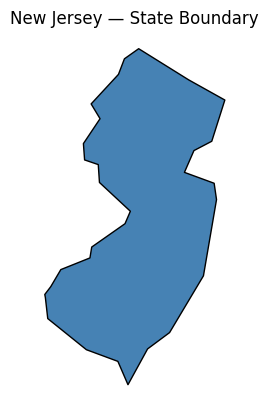

In [7]:
# Filter to New Jersey — same boolean indexing as pandas
nj = states[states["name"] == "New Jersey"].copy()

# .plot() renders a quick map of the geometry
nj.plot(edgecolor="black", color="steelblue")
plt.title("New Jersey — State Boundary")
plt.axis("off")
plt.show()

**Reflection:** What does the map show that a row in a table cannot?

# 6. Coordinate Reference Systems (CRS)

A CRS defines how the numbers in a geometry column relate to real locations on Earth.

## Geographic CRS
Coordinates are **longitude and latitude** in degrees.
Example: `EPSG:4326` (WGS 84) — the standard for GPS and most raw data.

## Projected CRS
The curved Earth surface is "unrolled" onto a flat plane using linear units (meters or feet).
Projected CRS are needed for accurate **distance, area, and buffer** calculations.

For New Jersey:
| EPSG | Name | Units | Use |
|---|---|---|---|
| 4326 | WGS 84 | Degrees | Raw data, web maps |
| 32618 | UTM Zone 18N | Meters | Measurement, analysis |
| 3424 | NJ State Plane | US Survey Feet | NJ agency data |

> **Rule:** Always check `.crs` before combining layers. Mismatched CRS causes silent errors.

In [8]:
# Check the CRS of the NJ layer
print("Current CRS:", nj.crs)

# Reproject to UTM Zone 18N — good for measuring distance/area in NJ
nj_utm = nj.to_crs(epsg=32618)
print("Reprojected CRS:", nj_utm.crs)

# Notice the coordinate scale change: degrees → meters
print("\nBounds in degrees (EPSG:4326):", nj.total_bounds.round(4))
print("Bounds in meters  (EPSG:32618):", nj_utm.total_bounds.round(0))

Current CRS: EPSG:4326
Reprojected CRS: EPSG:32618

Bounds in degrees (EPSG:4326): [-75.562   38.9939 -73.9025  41.3599]
Bounds in meters  (EPSG:32618): [ 451772. 4316116.  592308. 4578756.]


# Exercise 2 — CRS Practice

Use the code above as a reference to complete the cell below.

In [17]:
# YOUR TURN
# 1. Print the CRS of the original 'states' GeoDataFrame
print("States CRS:", states.crs)

# 2. Reproject 'nj' to NJ State Plane (EPSG:3424) and print the new CRS
nj_stateplane = nj.to_crs(epsg=3424)
print("NJ State Plane CRS:", nj_stateplane.crs)

# 3. Why would NJ State Plane (feet) be used instead of UTM Zone 18N (meters)?
ANSWER: ...

States CRS: EPSG:4326
NJ State Plane CRS: EPSG:3424


## Visualising the Effect of Reprojection

The same geometry looks different depending on the CRS — especially at a state or national scale.

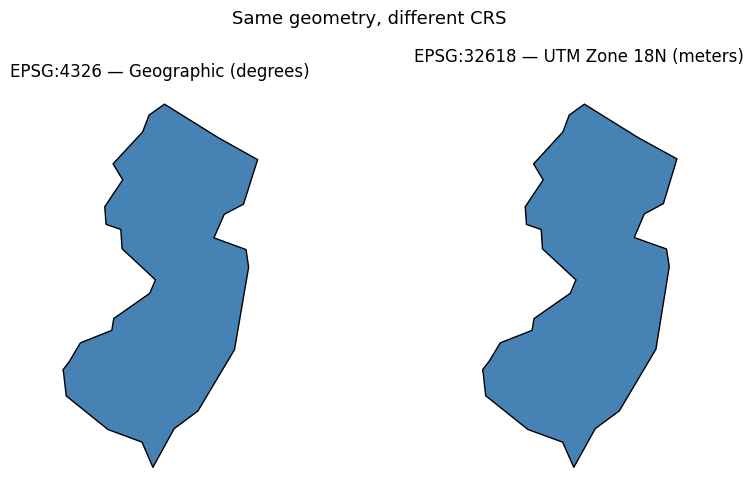

In [9]:
# Plot NJ in two projections side-by-side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

nj.plot(ax=axes[0], edgecolor="black", color="steelblue")
axes[0].set_title("EPSG:4326 — Geographic (degrees)")
axes[0].set_axis_off()

nj_utm.plot(ax=axes[1], edgecolor="black", color="steelblue")
axes[1].set_title("EPSG:32618 — UTM Zone 18N (meters)")
axes[1].set_axis_off()

plt.suptitle("Same geometry, different CRS", fontsize=13)
plt.tight_layout()
plt.show()

## Why CRS Matching Matters

When you overlay or join two spatial layers, they **must share the same CRS**.
Mismatched CRS is one of the most common sources of silent errors in GIS work — features appear in the wrong place or joins produce no results.

In [10]:
# Simulate a CRS mismatch scenario
# Suppose we load a second layer that arrived in a different CRS
nj_latlon   = nj.to_crs(epsg=4326)    # degrees
nj_statplane = nj.to_crs(epsg=3424)   # NJ State Plane (US Survey Feet)

print("Layer A CRS:", nj_latlon.crs)
print("Layer B CRS:", nj_statplane.crs)
print("Do they match?", nj_latlon.crs == nj_statplane.crs)  # False!

# Fix: align both layers to the same CRS before combining
nj_statplane_aligned = nj_statplane.to_crs(nj_latlon.crs)
print("After .to_crs() alignment — match?", nj_latlon.crs == nj_statplane_aligned.crs)

Layer A CRS: EPSG:4326
Layer B CRS: EPSG:3424
Do they match? False
After .to_crs() alignment — match? True


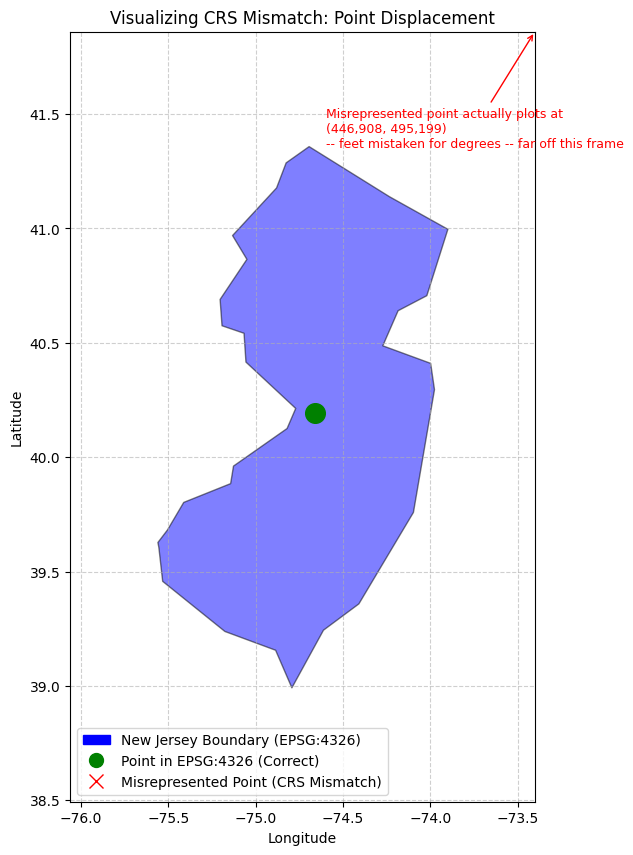

In [11]:
# Let's see what happens when CRS are mismatched

import matplotlib.patches as mpatches
from shapely.geometry import Point

fig, ax = plt.subplots(figsize=(10, 10))

# 1. Plot the New Jersey boundary in its correct CRS (Lat/Lon)
nj_latlon.plot(ax=ax, color='blue', edgecolor='black', alpha=0.5)

# 2. Get a representative point (e.g., centroid of NJ) in EPSG:4326
#    We'll take the centroid of the first geometry in the GeoDataFrame
representative_point_latlon = nj_latlon.geometry.iloc[0].centroid
point_latlon_gdf = gpd.GeoDataFrame([{'id': 1}], geometry=[representative_point_latlon], crs=nj_latlon.crs)

# 3. Reproject this point to EPSG:3424 (NJ State Plane) to get its *true* coordinates in that CRS
point_statplane_true = point_latlon_gdf.to_crs(epsg=3424)

# 4. Extract the coordinates from point_statplane_true
#    These coordinates are in US Survey Feet but will be plotted as if they were Lat/Lon degrees.
misrepresented_point_x = point_statplane_true.geometry.x.iloc[0]
misrepresented_point_y = point_statplane_true.geometry.y.iloc[0]

# Plot the correctly located point in Lat/Lon
point_latlon_gdf.plot(ax=ax, marker='o', color='green', markersize=200, label='Point in EPSG:4326 (Correct)')

# Plot the misrepresented point directly using ax.plot() to avoid geopandas aspect calculation issues
ax.plot(misrepresented_point_x, misrepresented_point_y,
        marker='x', color='red', markersize=10, linestyle='None',
        label='Coordinates from EPSG:3424 plotted as if EPSG:4326 (Mismatch)')

ax.set_title("Visualizing CRS Mismatch: Point Displacement")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# Zoom to New Jersey's real extent. Without this, matplotlib autoscales to
# include the misrepresented point's huge feet-based coordinates, and the
# entire state shrinks to an invisible dot in the corner of the plot.
minx, miny, maxx, maxy = nj_latlon.total_bounds
ax.set_xlim(minx - 0.5, maxx + 0.5)
ax.set_ylim(miny - 0.5, maxy + 0.5)

# The misrepresented point is now off-frame (that's the whole point -- it is
# ~500,000 feet-as-degrees away from where it belongs). Annotate its true
# plotted coordinates and direction so students can see *why* it's missing,
# instead of the point silently vanishing.
ax.annotate(
    f"Misrepresented point actually plots at\n"
    f"({misrepresented_point_x:,.0f}, {misrepresented_point_y:,.0f})\n"
    f"-- feet mistaken for degrees -- far off this frame",
    xy=(1.0, 1.0), xycoords="axes fraction",
    xytext=(0.55, 0.85), textcoords="axes fraction",
    fontsize=9, color="red",
    arrowprops=dict(arrowstyle="->", color="red"),
    clip_on=False,
)

# Create proxy artists for the legend
blue_patch = mpatches.Patch(color='blue', label='New Jersey Boundary (EPSG:4326)')
green_marker = plt.Line2D([], [], color='green', marker='o', linestyle='None', markersize=10, label='Point in EPSG:4326 (Correct)')
red_marker = plt.Line2D([], [], color='red', marker='x', linestyle='None', markersize=10, label='Misrepresented Point (CRS Mismatch)')

ax.legend(handles=[blue_patch, green_marker, red_marker])

plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

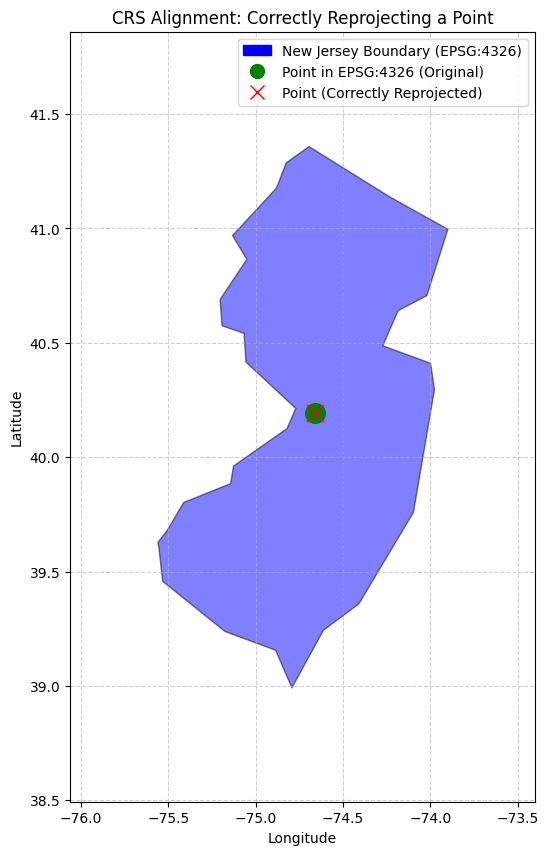

In [12]:
#Now align the coordinates to fix the issue

fig, ax = plt.subplots(figsize=(10, 10))

# 1. Plot the New Jersey boundary in its correct CRS (Lat/Lon)
nj_latlon.plot(ax=ax, color='blue', edgecolor='black', alpha=0.5, label='New Jersey Boundary (EPSG:4326)')

# 2. Plot the correctly located point in Lat/Lon
point_latlon_gdf.plot(ax=ax, marker='o', color='green', markersize=200, label='Point in EPSG:4326 (Original)')

# 3. Reproject the point back to EPSG:4326 so it aligns
point_statplane_reprojected_to_latlon = point_statplane_true.to_crs(nj_latlon.crs)

# 4. Plot the correctly reprojected point. It should now be visible and align with the green point.
point_statplane_reprojected_to_latlon.plot(ax=ax, marker='x', color='red', markersize=150, alpha=0.7, label='Point (from EPSG:3424, CORRECTLY Reprojected to EPSG:4326)')

ax.set_title("CRS Alignment: Correctly Reprojecting a Point")

# 5. Set plot limits based on the nj_latlon bounds
minx, miny, maxx, maxy = nj_latlon.total_bounds
ax.set_xlim(minx - 0.5, maxx + 0.5)
ax.set_ylim(miny - 0.5, maxy + 0.5)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# 6. Create proxy artists for the legend
blue_patch = mpatches.Patch(color='blue', label='New Jersey Boundary (EPSG:4326)')
green_marker = plt.Line2D([], [], color='green', marker='o', linestyle='None', markersize=10, label='Point in EPSG:4326 (Original)')
red_marker = plt.Line2D([], [], color='red', marker='x', linestyle='None', markersize=10, label='Point (Correctly Reprojected)')

ax.legend(handles=[blue_patch, green_marker, red_marker])

plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 7. Working with Points and Lines

GeoPandas handles all three vector geometry types in the same way.
Here we create a small dataset of Rutgers campus locations to practice with point geometry.

In [13]:
from shapely.geometry import Point

# A small set of Rutgers University campus points (approximate coordinates)
rutgers_campuses = gpd.GeoDataFrame(
    {
        "campus": ["College Avenue", "Busch", "Livingston", "Cook/Douglass"],
        "city":   ["New Brunswick", "Piscataway", "Piscataway", "New Brunswick"],
    },
    geometry=[
        Point(-74.4474, 40.4996),
        Point(-74.4641, 40.5218),
        Point(-74.4388, 40.5237),
        Point(-74.4735, 40.4836),
    ],
    crs="EPSG:4326"
)

print("Geometry type:", rutgers_campuses.geometry.geom_type.unique())
rutgers_campuses

Geometry type: ['Point']


,campus,city,geometry
0,College Avenue,New Brunswick,POINT (-74.4474 40.4996)
1,Busch,Piscataway,POINT (-74.4641 40.5218)
2,Livingston,Piscataway,POINT (-74.4388 40.5237)
3,Cook/Douglass,New Brunswick,POINT (-74.4735 40.4836)


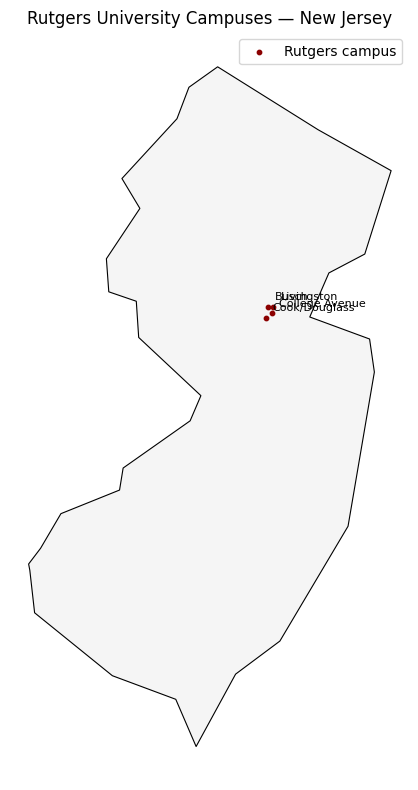

In [14]:
# Plot point layer on top of NJ state boundary
fig, ax = plt.subplots(figsize=(6, 8))

nj.plot(ax=ax, color="whitesmoke", edgecolor="black", linewidth=0.8)

rutgers_campuses.plot(
    ax=ax,
    color="darkred",
    markersize=10,
    marker="o",
    label="Rutgers campus"
)

# Label each point
for _, row in rutgers_campuses.iterrows():
    ax.annotate(
        row["campus"],
        xy=(row.geometry.x, row.geometry.y),
        xytext=(5, 5), textcoords="offset points",
        fontsize=8
    )

ax.set_title("Rutgers University Campuses — New Jersey")
ax.set_axis_off()
ax.legend()
plt.tight_layout()
plt.show()

**Reflection:** What information can you read from a point map that a table of addresses cannot provide?

# 8. Exporting Spatial Data

GeoPackage (`.gpkg`) is a modern, portable format that stores geometry and attributes together.
The file you export here will be your starting point for Workshop 2.

In [15]:
# Export the NJ boundary in UTM projection — ready for analysis in Workshop 2
output_path = "gis1_nj_boundary_utm.gpkg"
nj_utm.to_file(output_path, layer="nj_boundary", driver="GPKG")

print("Exported:", output_path)
print("CRS:", nj_utm.crs)
print("Rows:", len(nj_utm))

Exported: gis1_nj_boundary_utm.gpkg
CRS: EPSG:32618
Rows: 1


# 9. Reflection Exercise

Answer the following in your own words:

1. **What is the geometry column** in a GeoDataFrame, and why does it matter?

2. **Why does CRS matter** before combining two spatial layers?

3. **What is the difference** between a geographic CRS (like EPSG:4326) and a projected CRS (like EPSG:32618)?

4. **What spatial question** would you want to answer using NJ digital equity data and a map?

**Your responses:**
...

# Extension — Prepare for GIS Workshop 2

In Workshop 2 you will:
- Load official **NJ county boundaries** from the US Census Bureau
- Join the **NJ Digital Equity dataset** to county polygons
- Create a styled **choropleth map** showing broadband access by county
- Perform a **spatial join** to find which points fall within which polygons
- Export a complete spatial analysis dataset

**Before Workshop 2, try:**
1. Find one NJ public dataset online (data.nj.gov is a good starting point)
2. Identify its geometry type and format
3. Write one spatial question you could answer with it

# Key Takeaways

- Spatial data combines **attributes** (what) with **geometry** (where).
- The three vector geometry types are **point**, **line**, and **polygon**.
- Always check `.crs` before working with spatial data.
- Use `.to_crs()` to reproject — required for accurate distance and area measurements.
- `gpd.read_file()` reads spatial data from URLs, files, and zipped shapefiles.
- GeoPandas `.plot()` is the quickest way to inspect spatial data visually.
- Workshop 2 will go deeper: joins, choropleths, and spatial analysis.